# 뉴런을 읽기 ② — 상대 이론: 왜 다들 뉴런은 섞여 있다고 믿었나

Goodfire의 논문이 뉴스가 된 이유는, 그 전의 통념과 반대되는 말을 했기 때문이다. 통념은 이랬다.

> 모델은 표현해야 할 특징이 차원(뉴런 수)보다 훨씬 많다. 그래서 특징을 **겹쳐 담는다(superposition)**. 뉴런 하나에는 여러 특징이 섞이고(polysemantic), 해석하려면 SAE 같은 사전으로 다시 풀어야 한다.

이 권은 그 통념의 근거가 된 장난감 모델(Elhage et al. 2022, *Toy Models of Superposition*)을 직접 돌린다. 목적은 둘이다. 통념이 **어떤 조건에서** 참인지 정확히 아는 것, 그리고 그 조건이 깨지면 무슨 일이 생기는지 보는 것이다. 그래야 논문의 주장이 실제 모델의 **무엇에 대한** 주장인지 알 수 있다.

ARENA 1.5.4의 §1(비특권 기저), §2(특권 기저), §5(장난감 SAE)를 골라 순서를 다시 짰고, 에세이 *Already Clean*의 반론 실험(함께 켜지는 입력 묶음)을 더했다. 전부 CPU에서 몇 분이면 돈다.

## 학습 목표, 필수 경로, stop rule

1. 특징이 차원보다 많을 때 모델이 언제 겹쳐 담고 언제 버리는지, **희소도**를 바꿔 가며 본다.
2. **특권 기저**가 무엇인지 식과 실험으로 말한다. ① Cell 07에서 보류한 질문(뉴런 축은 다른 방향과 다른가)이 여기서 이름을 얻는다.
3. 특권 기저에서 희소도가 커지면 뉴런이 섞이는 것(polysemantic)을 본다.
4. 특징들이 **함께 켜지면** 어떻게 바뀌는지 본다(에세이의 반론).
5. 같은 장난감에서 **뉴런과 SAE 중 누가 특징을 찾는지**가 무엇으로 갈리는지 본다.

**필수 경로:** Cell 01–07. 전체 CPU 약 3–4분.

### ③으로 넘어가도 되는 기준 (stop rule)

- "특징이 차원보다 많으면 뉴런이 섞인다"가 어떤 가정(희소하다, 서로 독립이다, 특권 기저가 있다)에서 나오는지 말하고, 그 가정 하나가 깨질 때(함께 켜짐) 무슨 일이 생기는지 이 권의 숫자로 말할 수 있다.
- 장난감에서 뉴런과 SAE 중 누가 특징을 찾는지가 무엇으로 갈렸는지 말하고, 그래서 Goodfire의 주장이 실제 언어모델의 **어떤 성질**에 대한 경험적 주장인지 한 문장으로 쓸 수 있다.

표시는 ①과 같다. **[정의] [대수] [측정] [근사]**, **✍️ 예측**(실행 전에 적는다).

## 공통 setup

#### Cell 01 · 실행 환경

- **이번 셀의 질문:** 환경이 같은가?
- **출력에서 볼 것:** 버전.
- **해석 범위:** 모델을 내려받지 않는다. 장난감 모델은 이 notebook 안에서 학습한다.

In [1]:
import sys
from pathlib import Path

HERE = Path.cwd()
if not (HERE / "toy_lab.py").exists():
    HERE = next(p for p in [HERE / "chapter1_transformer_interp/exercises/part35_neurons_ko", *HERE.parents]
                if (p / "toy_lab.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import torch

import neuron_lab as nl
import toy_lab as toy
nl.pl.use_style()
print("torch", torch.__version__)

torch 2.15.0+cpu


## 1. 비특권 기저: 겹쳐 담기

#### [정의] 장난감 모델 A

특징 $n=5$개를 $m=2$차원에 담았다가 다시 꺼낸다.

$$h = W x \in \mathbb{R}^2, \qquad x' = \mathrm{ReLU}(W^\top h + b), \qquad \text{손실} = \sum_i I_i\,(x_i - x'_i)^2$$

- 특징 $x_i$는 확률 $1-S$로 켜지고, 켜지면 0과 1 사이의 균등분포 값이다. $S$가 **희소도**다($S=0.99$면 100번에 1번 켜진다).
- 중요도 $I_i = 0.9^i$: 앞의 특징일수록 조금 더 중요하다.
- $W$의 $i$번째 열 $W_i$가 특징 $i$가 2차원 안에서 놓이는 방향이다. $\lVert W_i\rVert \approx 1$이면 그 특징을 담았고, $\approx 0$이면 버렸다.
- [정의] 겹침: $\sum_{j\neq i} (\hat W_i\cdot W_j)^2$. 0이면 다른 특징과 직교하고, 클수록 다른 특징과 같은 자리를 나눠 쓴다.

2차원에는 서로 직교하는 방향이 2개뿐이다. 그러면 특징은 2개만 담겨야 할 것 같다.

**✍️ 예측 1.** 희소도 $S$를 0, 0.5, 0.8, 0.9, 0.95, 0.99로 바꿔 가며 학습한다. 각 $S$에서 2차원에 담기는 특징($\lVert W_i\rVert>0.5$)은 몇 개일까? $S=0$과 $S=0.99$는 특히 확신을 가지고 적고, 이유를 한 줄 붙인다.

#### Cell 02 · 희소도를 바꾸며 모델 A 학습

- **이번 셀의 질문:** 희소할수록 더 많은 특징을 겹쳐 담는가?
- **출력에서 볼 것:** 희소도마다 담긴 특징 수, 특징별 $\lVert W_i\rVert$와 겹침, 그리고 2차원 그림.
- **해석 범위:** seed 4개 중 손실이 가장 낮은 것을 쓴다. 특징 5개, 차원 2개라는 아주 작은 설정이다.

S=0.0  : 담긴 특징 2개   ‖W_i‖ [1.   1.   0.03 0.   0.  ]   겹침 [0. 0. 1. 1. 1.]
S=0.5  : 담긴 특징 4개   ‖W_i‖ [1.   1.   0.93 0.93 0.  ]   겹침 [0.86 0.86 0.99 1.   1.86]
S=0.8  : 담긴 특징 4개   ‖W_i‖ [1.01 1.01 1.01 1.01 0.01]   겹침 [1.01 1.01 1.03 1.03 2.04]
S=0.9  : 담긴 특징 5개   ‖W_i‖ [1.11 1.11 1.1  1.09 1.07]   겹침 [1.79 1.78 1.83 1.8  1.84]
S=0.95 : 담긴 특징 5개   ‖W_i‖ [1.15 1.13 1.14 1.13 1.12]   겹침 [1.92 1.91 1.91 1.95 1.93]
S=0.99 : 담긴 특징 5개   ‖W_i‖ [1.16 1.17 1.16 1.16 1.15]   겹침 [2.01 2.03 2.03 2.02 2.02]


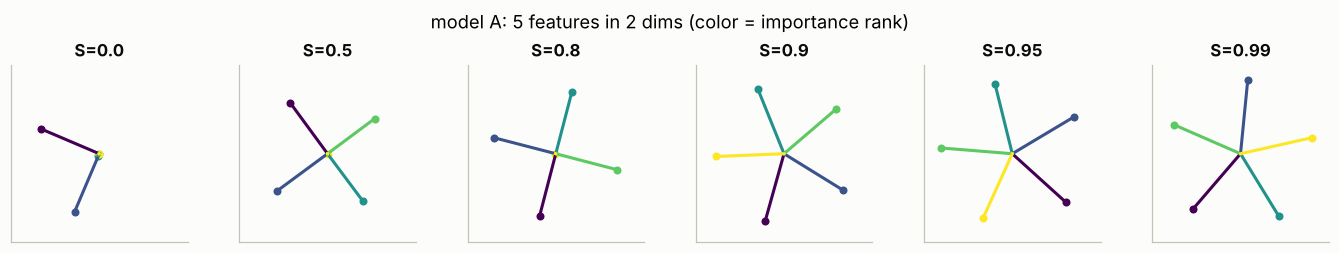

In [2]:
S_LIST = [0.0, 0.5, 0.8, 0.9, 0.95, 0.99]
W_A, b_A, L_A = toy.best_of([0, 1, 2, 3], n_inst=len(S_LIST), n_feat=5, m=2,
                            data=toy.indep_data(len(S_LIST), 5, S_LIST), imp=0.9)
res_A = []
for i, S in enumerate(S_LIST):
    norms = W_A[i].norm(dim=0)
    res_A.append(dict(S=S, n_rep=int((norms > 0.5).sum()), norms=norms.numpy().round(2),
                      interference=toy.interference(W_A[i]).numpy().round(2), loss=float(L_A[i])))
    print(f"S={S:<5}: 담긴 특징 {res_A[-1]['n_rep']}개   ‖W_i‖ {res_A[-1]['norms']}   겹침 {res_A[-1]['interference']}")

fig, axes = plt.subplots(1, len(S_LIST), figsize=(2.1 * len(S_LIST), 2.3))
for ax, i in zip(axes, range(len(S_LIST))):
    for j in range(5):
        w = W_A[i][:, j].numpy()
        ax.plot([0, w[0]], [0, w[1]], c=plt.cm.viridis(j / 4), lw=2)
        ax.scatter(*w, color=plt.cm.viridis(j / 4), s=18)
    ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"S={S_LIST[i]}")
plt.suptitle("model A: 5 features in 2 dims (color = importance rank)"); plt.tight_layout(); plt.show()

**읽는 법.**
- $S=0$(늘 켜짐): 가장 중요한 특징 2개만 직교하게 담고 나머지 셋은 버린다. 주성분 분석과 같은 답이다.
- 중간 희소도: 특징 4개를 담는다. 두 쌍이 서로 **반대 방향**(대척점)에 놓인다. 겹침이 1 근처다. 한 쌍의 두 특징은 같은 선을 나눠 쓰고, 동시에 켜질 때만 서로 방해한다. 희소하면 그런 일이 드물다.
- 높은 희소도: 5개 전부를 오각형으로 담는다. 겹침이 2 근처다. 특징이 차원보다 많은데도 모두 담겼다. 이것이 **superposition**이다.
- 핵심 조건은 희소도다. 특징이 드물게 켜질수록 겹쳐 담는 비용(동시에 켜질 때의 방해)이 작아진다.

## 2. 특권 기저: 왜 뉴런 축이 특별할 수 있나

#### [대수] 모델 A에는 특별한 축이 없다

은닉 공간을 아무 직교행렬 $R$로 돌린다: $W \to RW$. 그러면

$$x' = \mathrm{ReLU}\big((RW)^\top (RW)\,x + b\big) = \mathrm{ReLU}(W^\top R^\top R\, W x + b) = \mathrm{ReLU}(W^\top W x + b)$$

로 같다. 모델 A의 은닉 좌표축은 이름일 뿐이다. 그래서 "은닉 1번 좌표가 무엇을 뜻하나"는 의미 없는 질문이다. 이것이 **비특권 기저**다. Transformer의 residual stream이 이렇다(1.3.1이 방향만 신경 쓰고 기저는 신경 쓰지 않은 이유).

#### [정의] 모델 B: 은닉 좌표마다 ReLU

$$h = \mathrm{ReLU}(W x), \qquad x' = \mathrm{ReLU}(W^\top h + b)$$

이제 $\mathrm{ReLU}(RWx) \neq R\,\mathrm{ReLU}(Wx)$이다. ReLU가 **좌표마다 따로** 걸리기 때문이다. 좌표축을 돌리면 다른 함수가 된다. 이 좌표축이 **뉴런**이고, 이런 기저를 **특권 기저**라 한다. ①의 SwiGLU도 같다. SiLU와 곱셈이 뉴런마다 따로 걸린다.

**✍️ 예측 2.** $S=0.9$에서 학습한 모델 A와 모델 B의 은닉 공간을 같은 무작위 직교행렬로 돌린다. 손실은 각각 어떻게 될까?

#### Cell 03 · 돌려 보기: 특권 기저의 검사

- **이번 셀의 질문:** 은닉 공간을 돌리면 모델이 바뀌는가?
- **출력에서 볼 것:** 돌리기 전후의 손실, 모델 A와 B.
- **해석 범위:** [대수]가 실제로 성립하는지 확인하는 셀이다. 모델 B는 다음 셀에서 학습한 것을 미리 쓴다(특징 10개, 뉴런 5개).

In [3]:
S_B = [0.0, 0.5, 0.8, 0.9, 0.95, 0.99]
W_B, b_B, L_B = toy.best_of([0, 1, 2], n_inst=len(S_B), n_feat=10, m=5,
                            data=toy.indep_data(len(S_B), 10, S_B), priv=True, imp=0.75)

def loss_of(W, b, S, n_feat, priv, imp, seed=123):
    g = torch.Generator().manual_seed(seed)
    x = toy.indep_data(1, n_feat, [S])(8192, g)
    _, out = toy.forward(W[None], b[None], x, priv)
    I = imp ** torch.arange(n_feat).float()
    return float((I * (out - x) ** 2).mean())

torch.manual_seed(7)
i_A, i_B = S_LIST.index(0.9), S_B.index(0.9)
R2, _ = torch.linalg.qr(torch.randn(2, 2))
R5, _ = torch.linalg.qr(torch.randn(5, 5))
rot = {
    "A (h = Wx)": (loss_of(W_A[i_A], b_A[i_A], 0.9, 5, False, 0.9), loss_of(R2 @ W_A[i_A], b_A[i_A], 0.9, 5, False, 0.9)),
    "B (h = ReLU(Wx))": (loss_of(W_B[i_B], b_B[i_B], 0.9, 10, True, 0.75), loss_of(R5 @ W_B[i_B], b_B[i_B], 0.9, 10, True, 0.75)),
}
for k, (before, after) in rot.items():
    print(f"{k:18s}: 손실 {before:.5f} → 돌린 뒤 {after:.5f}  (×{after / before:.2f})")

A (h = Wx)        : 손실 0.00409 → 돌린 뒤 0.00409  (×1.00)
B (h = ReLU(Wx))  : 손실 0.00171 → 돌린 뒤 0.00728  (×4.26)


**읽는 법.** 모델 A는 돌려도 손실이 같다. 모델 B는 돌리면 손실이 몇 배로 뛴다. 모델 B에서는 뉴런 축이 학습된 해의 일부다. 그래서 "뉴런 하나가 무엇을 뜻하나"를 물을 **자격**이 생긴다. 다만 자격이 있다는 것이 그 답이 깨끗하다는 뜻은 아니다. 그것이 다음 셀의 질문이다.

① Cell 07로 돌아가면, 무작위 방향과 뉴런을 비교하는 것은 "특권 기저가 있다(구조상)"가 아니라 "그 특권이 우리가 고른 개념(참/거짓)과 맞는가"를 묻는 것이었다. 둘은 다른 질문이다.

## 3. 특권 기저에서 뉴런은 섞이는가

[정의] 뉴런 $k$가 특징 $i$를 담는다 = $|W_{ki}| > 0.3$이고 특징 $i$가 담겨 있다($\lVert W_i\rVert > 0.5$). 뉴런 하나가 담는 특징 수가 1이면 **단의미(monosemantic)**, 여럿이면 **다의미(polysemantic)** 다. 기준 0.3은 이 교재가 정한 것이다([근사]).

**✍️ 예측 3.** 모델 B(특징 10개, 뉴런 5개)에서, 희소도가 낮을 때($S=0$)와 높을 때($S=0.99$) 각각 (가) 담긴 특징은 몇 개, (나) 뉴런 하나가 담는 특징은 몇 개일까?

#### Cell 04 · 희소도와 다의미 뉴런

- **이번 셀의 질문:** 특권 기저가 있어도, 희소하면 뉴런이 섞이는가?
- **출력에서 볼 것:** 희소도마다 담긴 특징 수와 뉴런별로 담는 특징 수. 두 희소도의 $W$ 그림.
- **해석 범위:** $W$의 크기 기준(0.3, 0.5)이 결과를 조금 바꿀 수 있다. 경향을 본다.

S=0.0  : 담긴 특징  5개 / 10   뉴런별로 담는 특징 수 [1, 1, 1, 1, 1]
S=0.5  : 담긴 특징  5개 / 10   뉴런별로 담는 특징 수 [1, 1, 1, 1, 1]
S=0.8  : 담긴 특징  7개 / 10   뉴런별로 담는 특징 수 [5, 5, 1, 5, 5]
S=0.9  : 담긴 특징  8개 / 10   뉴런별로 담는 특징 수 [7, 1, 7, 7, 6]
S=0.95 : 담긴 특징  8개 / 10   뉴런별로 담는 특징 수 [1, 7, 7, 7, 7]
S=0.99 : 담긴 특징  9개 / 10   뉴런별로 담는 특징 수 [9, 8, 7, 8, 9]


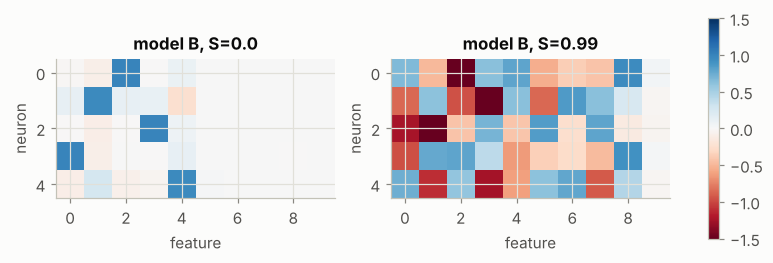

In [4]:
res_B = []
for i, S in enumerate(S_B):
    W = W_B[i]
    rep = W.norm(dim=0) > 0.5
    per_neuron = ((W.abs() > 0.3) & rep[None]).sum(1).tolist()
    res_B.append(dict(S=S, n_rep=int(rep.sum()), per_neuron=per_neuron, loss=float(L_B[i])))
    print(f"S={S:<5}: 담긴 특징 {int(rep.sum()):2d}개 / 10   뉴런별로 담는 특징 수 {per_neuron}")

fig, axes = plt.subplots(1, 2, figsize=(9, 2.6))
for ax, S in zip(axes, [0.0, 0.99]):
    i = S_B.index(S)
    im = ax.imshow(W_B[i].numpy(), cmap="RdBu", vmin=-1.5, vmax=1.5)
    ax.set(title=f"model B, S={S}", xlabel="feature", ylabel="neuron")
plt.colorbar(im, ax=axes); plt.show()

**읽는 법.** 희소도가 낮으면 뉴런 5개가 특징 5개를 하나씩 맡는다. 뉴런이 곧 특징이다. 희소도가 높아지면 담기는 특징이 늘고(10개 중 8–9개), 뉴런 하나가 여러 특징을 담는다. 특권 기저가 있어도, **특징이 희소하고 서로 독립이면** 뉴런은 섞인다. 이것이 "뉴런은 polysemantic이다, 그러니 SAE가 필요하다"는 통념의 장난감 근거다.

## 4. 반론: 특징이 함께 켜지면

통념의 가정 하나는 **특징이 서로 독립**이라는 것이다. 실제 언어에서는 그렇지 않다. "각막", "혼탁", "LASIK"은 같은 문서에 함께 나온다. 에세이 *Already Clean*은 이 점을 반론으로 든다. 함께 켜지는 특징이 묶음을 이루면, 모델은 겹쳐 담는 대신 **묶음마다 뉴런을 하나씩** 쓰게 된다는 것이다.

[정의] 묶음 데이터: 특징 20개를 5개씩 4묶음으로 나눈다. 묶음 하나가 확률 0.1로 켜지면 그 안의 특징 5개가 모두 켜지고, 값은 각자 균등분포다. 비교군은 같은 특징 20개가 **각자 독립으로** 확률 0.1씩 켜지는 데이터다. 특징 하나만 보면 두 데이터의 켜지는 빈도가 같다. 둘 다 모델 B(특권 기저), 뉴런 5개, 중요도는 모두 같다.

[정의] 뉴런의 묶음 순도: 뉴런 $k$의 가중치 제곱합 중 가장 큰 묶음이 차지하는 비율. 1이면 한 묶음만, 0.25면 네 묶음에 고르게 퍼져 있다.

**✍️ 예측 4.** 두 데이터에서 (가) 뉴런의 묶음 순도는 각각 어떨까? (나) 손실은 어느 쪽이 낮을까? (다) 묶음 데이터에서 뉴런 하나가 묶음 하나를 맡는다면, 그 뉴런은 묶음 안의 특징 5개를 **따로따로** 복원할 수 있을까?

#### Cell 05 · 함께 켜지는 묶음 vs 독립

- **이번 셀의 질문:** 특징이 함께 켜지면 뉴런은 무엇을 맡는가?
- **출력에서 볼 것:** 두 데이터의 손실, 뉴런별 묶음 순도, $W$ 그림.
- **해석 범위:** 독립 데이터의 '묶음'은 이름표일 뿐이다(그 데이터에는 묶음 구조가 없다). 묶음 순도는 비교 기준으로만 본다.

묶음: 손실 0.0054   뉴런별 묶음 순도 [0.94 0.92 0.93 0.92 0.25]
독립: 손실 0.0186   뉴런별 묶음 순도 [0.42 0.41 0.31 0.55 0.68]
손실 비 (독립 / 묶음) 3.5


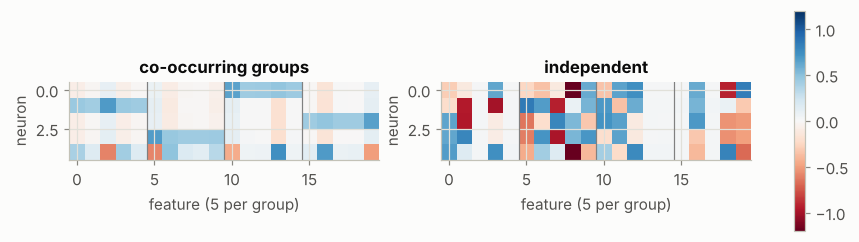

In [5]:
G, SIZE, P_ON = 4, 5, 0.1
gd = toy.group_data(1, G, SIZE, P_ON)
idd = toy.indep_data(1, G * SIZE, [1 - P_ON])
both = lambda bs, g: torch.cat([gd(bs, g), idd(bs, g)], 1)   # instance 0 = 묶음, 1 = 독립
W_C, b_C, L_C = toy.best_of([0, 1, 2], n_inst=2, n_feat=G * SIZE, m=5, data=both, priv=True)

res_C = {}
for k, name in enumerate(["묶음", "독립"]):
    mass = (W_C[k] ** 2).reshape(5, G, SIZE).sum(2)          # [뉴런, 묶음]
    purity = (mass.max(1).values / mass.sum(1)).numpy().round(2)
    res_C[name] = dict(loss=float(L_C[k]), purity=purity, dominant=mass.argmax(1).tolist())
    print(f"{name}: 손실 {L_C[k]:.4f}   뉴런별 묶음 순도 {purity}")
print(f"손실 비 (독립 / 묶음) {L_C[1] / L_C[0]:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 2.6))
for ax, k, name in zip(axes, [0, 1], ["co-occurring groups", "independent"]):
    im = ax.imshow(W_C[k].numpy(), cmap="RdBu", vmin=-1.2, vmax=1.2)
    for s in range(1, G):
        ax.axvline(s * SIZE - 0.5, c="gray", lw=0.8)
    ax.set(title=name, xlabel="feature (5 per group)", ylabel="neuron")
plt.colorbar(im, ax=axes); plt.show()

**읽는 법.**
- 묶음 데이터에서는 뉴런 4개가 묶음 하나씩을 거의 혼자 맡는다(순도 0.9 이상). 다섯째 뉴런은 여러 묶음에 걸친다. 독립 데이터에서는 모든 뉴런이 여러 묶음에 퍼진다. 같은 모델 구조, 같은 특징별 빈도인데, **데이터의 상관 구조**만 바꿔서 뉴런이 단의미에 가까워졌다.
- (다)의 답: 못 한다. 묶음 뉴런 하나는 묶음 안의 특징 다섯 개에 거의 같은 무게로 쓴다. 그래서 다섯 특징의 개별 값이 아니라 "이 묶음이 얼마나 켜졌나"를 복원한다. 에세이의 표현으로 하면, 공간이 모자랄 때 모델은 특징을 **섞는** 대신 **거칠게** 담는다. 그 뉴런의 설명은 "각막 혼탁"이 아니라 "안과 수술 문서"처럼 넓은 말이 된다.
- 손실도 묶음 쪽이 훨씬 낮다. 상관이 있으면 담아야 할 정보 자체가 적다.

## 5. 뉴런이냐 사전이냐: 장난감 SAE

[정의] SAE(희소 오토인코더): 은닉 $h$를 더 많은 수의 잠재 단위 $z$로 풀었다가 다시 합친다. $z = \mathrm{ReLU}(W_e (h - b_d) + b_e)$, $\hat h = W_d^\top z + b_d$, 손실 $= \lVert \hat h - h\rVert^2 + \lambda \sum_j z_j$. 디코더 방향 $W_d$의 각 행이 SAE가 찾은 "특징 방향"이다.

[정의] 특징 $i$의 진짜 은닉 방향은 특징 하나만 켰을 때의 은닉 $\mathrm{ReLU}(W e_i)$이다. 이 방향과 cos이 0.9를 넘는 **SAE 디코더 방향**이 있으면 SAE가 그 특징을 찾은 것으로 센다. 같은 방향과 cos이 0.9를 넘는 **뉴런 축**(표준 기저 $e_k$)이 있으면 뉴런이 이미 그 특징인 것으로 센다.

SAE는 잠재 20개, $\lambda=0.2$로 모델 B의 은닉에 학습한다.

**✍️ 예측 5.** 모델 B의 희소도 0.5, 0.9, 0.99에서 담긴 특징 중 (가) 뉴런 축이 이미 그 특징인 것, (나) SAE가 찾은 것은 각각 몇 개일까? 어느 희소도에서 누가 이길까?

#### Cell 06 · 뉴런 축 vs SAE 디코더

- **이번 셀의 질문:** 누가 특징을 찾는가? 그것은 무엇으로 갈리는가?
- **출력에서 볼 것:** 희소도마다 담긴 특징 수, 뉴런으로 찾은 수, SAE로 찾은 수, SAE의 복원 오차(FVU)와 평균 활성 잠재 수(L0).
- **해석 범위:** SAE의 크기와 $\lambda$를 하나로 고정했다. 다른 설정에서는 SAE가 더 잘하거나 못할 수 있다([근사]). 진짜 특징을 아는 장난감이라서 '찾았다'를 셀 수 있다. 실제 언어모델에서는 진짜 특징을 모른다.

In [6]:
res_D = []
for S in [0.5, 0.9, 0.99]:
    W = W_B[S_B.index(S)]
    rep = W.norm(dim=0) > 0.5
    V = torch.relu(W).T                                   # [특징, 뉴런] 특징 하나만 켰을 때의 은닉
    Vn = V / V.norm(dim=1, keepdim=True).clamp(min=1e-8)
    sae = toy.train_sae(W, S)
    cos_sae = (Vn @ sae["W_dec"].T).max(1).values[rep]    # 특징마다 가장 가까운 SAE 방향
    cos_neuron = Vn.abs().max(1).values[rep]              # 특징마다 가장 가까운 뉴런 축
    res_D.append(dict(S=S, n_rep=int(rep.sum()), neuron=int((cos_neuron > 0.9).sum()), sae=int((cos_sae > 0.9).sum()),
                      fvu=sae["fvu"], L0=sae["L0"], alive=sae["alive"]))
    r = res_D[-1]
    print(f"S={S:<5}: 담긴 특징 {r['n_rep']:2d}   뉴런 축으로 찾음 {r['neuron']:2d}   SAE로 찾음 {r['sae']:2d}"
          f"   | SAE FVU {r['fvu']:.3f}, L0 {r['L0']:.2f}, 살아 있는 잠재 {r['alive']}/20")

S=0.5  : 담긴 특징  5   뉴런 축으로 찾음  5   SAE로 찾음  0   | SAE FVU 0.086, L0 3.29, 살아 있는 잠재 16/20


S=0.9  : 담긴 특징  8   뉴런 축으로 찾음  1   SAE로 찾음  8   | SAE FVU 0.063, L0 1.84, 살아 있는 잠재 20/20


S=0.99 : 담긴 특징  9   뉴런 축으로 찾음  0   SAE로 찾음  9   | SAE FVU 0.044, L0 0.16, 살아 있는 잠재 17/20


**읽는 법.**
- 희소도가 낮으면 뉴런 축이 이미 특징이다. 이때 SAE는 특징을 하나도 깨끗이 찾지 못한다. 잠재가 특징보다 많아서 특징 하나를 여러 잠재로 쪼개거나 섞는다. 복원은 잘하는데도 그렇다(FVU가 작다). **복원을 잘하는 사전이 곧 특징을 찾은 사전은 아니다.**
- 희소도가 높으면 뉴런은 섞여 있고 SAE가 특징을 거의 다 찾는다.
- 그래서 "뉴런이냐 SAE냐"의 답은 방법의 우열이 아니라 **데이터가 어떤 상태인가**(희소도, 상관 구조)로 갈린다. 장난감에서는 우리가 그 상태를 정했다. 실제 언어모델에서는 모른다.

## 6. 그래서 Goodfire의 주장은 무엇에 대한 주장인가

이 권의 장난감으로 보면, 논문의 주장은 **실제 언어모델이 어느 상태에 있는가**에 대한 경험적 주장이다. "LLM의 MLP는 셀 4(독립·희소, 섞임)보다 셀 5(묶음, 단의미에 가까움)에 가깝다"는 것이다. 장난감은 이 주장을 증명하지도 반박하지도 못한다. 장난감이 보여 주는 것은 **두 상태가 모두 가능하고, 무엇이 둘을 가르는가**다.

그러면 실제 모델에서 무엇을 재야 하는지가 정해진다. 이것이 ③④의 일이다.

| 장난감에서 가르던 것 | 실제 모델에서 재는 법 | 어느 권 |
|---|---|---|
| 뉴런 몇 개로 충분한가(묶음 뉴런은 소수가 강하게 켜진다) | 층마다 센 뉴런 $K$개만 남기고 손실 변화 | ③ |
| 뉴런 하나가 한 가지를 맡는가 | 뉴런마다 설명을 쓰고, 그 설명으로 활성을 예측 | ④ |
| 거칠게 담긴 뉴런의 설명은 넓은 말이 된다 | 설명이 얼마나 구체적인지, near miss로 시험 | ④ |
| SAE가 더 잘 찾는가 | 같은 층의 SAE와 맞대기 (논문에 없음) | ④ 또는 ⑤ |

① Cell 07의 보류도 여기서 다시 읽힌다. 모델이 특권 기저를 **가진다**는 것(Cell 03)과, 그 기저가 우리가 고른 개념 하나(참/거짓)에 **맞춰져 있다**는 것은 다르다. 묶음 뉴런은 "안과 문서"처럼 데이터가 함께 켜는 것에 맞춰진다. 참/거짓은 그런 묶음이 아닐 수 있다.

## 주장 장부

In [7]:
ledger = [
    ("특징이 희소하면 차원보다 많은 특징을 겹쳐 담는다", "유지 [측정, 장난감]", f"Cell 02: S=0에서 {res_A[0]['n_rep']}개, S=0.99에서 {res_A[-1]['n_rep']}개"),
    ("은닉 좌표마다 비선형이 걸리면 그 좌표축이 특권을 갖는다", "유지 [대수]", "Cell 03: 돌리면 B만 손실이 바뀐다"),
    ("특권 기저에서도 희소·독립이면 뉴런이 섞인다", "유지 [측정, 장난감]", f"Cell 04: S=0.99에서 뉴런별 특징 수 {res_B[-1]['per_neuron']}"),
    ("특징이 함께 켜지면 뉴런이 묶음 하나씩을 맡는다", "유지 [측정, 장난감]", f"Cell 05: 묶음 순도 {[round(float(v), 2) for v in res_C['묶음']['purity']]}"),
    ("SAE가 언제나 뉴런보다 특징을 잘 찾는다", "기각 [측정, 장난감]", f"Cell 06: S=0.5에서 뉴런 {res_D[0]['neuron']}, SAE {res_D[0]['sae']}"),
    ("실제 언어모델이 어느 상태에 있는가", "장난감으로는 판정 불가", "③④에서 잰다"),
]
for claim, status, ev in ledger:
    print(f"[{status}] {claim}\n    근거: {ev}")
nl.save_results("02_superposition", dict(model_A=res_A, rotation=rot, model_B=res_B, groups=res_C, sae=res_D, ledger=ledger))
print("\nresults/02_superposition.json 저장")

[유지 [측정, 장난감]] 특징이 희소하면 차원보다 많은 특징을 겹쳐 담는다
    근거: Cell 02: S=0에서 2개, S=0.99에서 5개
[유지 [대수]] 은닉 좌표마다 비선형이 걸리면 그 좌표축이 특권을 갖는다
    근거: Cell 03: 돌리면 B만 손실이 바뀐다
[유지 [측정, 장난감]] 특권 기저에서도 희소·독립이면 뉴런이 섞인다
    근거: Cell 04: S=0.99에서 뉴런별 특징 수 [9, 8, 7, 8, 9]
[유지 [측정, 장난감]] 특징이 함께 켜지면 뉴런이 묶음 하나씩을 맡는다
    근거: Cell 05: 묶음 순도 [0.94, 0.92, 0.93, 0.92, 0.25]
[기각 [측정, 장난감]] SAE가 언제나 뉴런보다 특징을 잘 찾는다
    근거: Cell 06: S=0.5에서 뉴런 5, SAE 0
[장난감으로는 판정 불가] 실제 언어모델이 어느 상태에 있는가
    근거: ③④에서 잰다

results/02_superposition.json 저장


## 구멍 장부

| 건너뛴 것 | 지금 알아 둘 한 줄 | 다시 나오는 곳 |
|---|---|---|
| 1.5.4 §3 특징 기하 (오각형, 사면체 같은 모양과 "차원 분수") | 겹쳐 담긴 특징들은 규칙적인 다면체 모양으로 놓인다 | 필요하면 나중에 |
| 1.5.4 §4 deep double descent | 학습 데이터 수에 따라 기억과 일반화가 바뀌며 superposition도 바뀐다 | 에세이가 인정한 반례(기억이 먼저 이기는 경우)와 이어짐. 가지 |
| 상전이 그림 (중요도 × 희소도) | 특징을 버릴지, 겹쳐 담을지, 따로 담을지가 두 값으로 갈린다 | 필요하면 나중에 |
| SAE 학습의 세부 (죽은 잠재, $\lambda$ 고르기, 디코더 정규화) | 이 권은 설정 하나만 썼다 | 1.3.3 §3, ④ |
| 묶음이 부분적으로만 겹칠 때 | 이 권은 묶음이 완전히 함께 켜지는 극단만 봤다 | ④에서 실제 데이터로 |